In [1]:
%load_ext autoreload
%autoreload 2

# STEP 0 - Download the Dataset from Kaggle

For this project, we will use the **BETH dataset** (Highnam et al., 2021). This dataset includes ~8 million datapoints spanning endpoint process events and DNS events across 23 endpoints. The data is collected via honeypots deployed by Highnam's team and labelled for cybersecurity anomaly and novelty detection. We will be focusing on the **endpoint process event data** and exclude the *DNS event data*.

The repo does not include the dataset. Use the cell below to download the 3 csv files for endpoint data into the repo's `/data/` folder if you'd like to rerun the notebook. There is no harm running this multiple times - it will simply overwrite the previous files.

In [2]:
from endpoint_anomaly_detection_beth.download import main as download_beth
download_beth()

Saved labelled_training_data.csv to C:\Users\jake\projects\endpoint-anomaly-detection-beth\data\labelled_training_data.csv (197.3 MB)
Saved labelled_testing_data.csv to C:\Users\jake\projects\endpoint-anomaly-detection-beth\data\labelled_testing_data.csv (57.3 MB)
Saved labelled_validation_data.csv to C:\Users\jake\projects\endpoint-anomaly-detection-beth\data\labelled_validation_data.csv (45.4 MB)


# STEP 1 - Observe the Data

Before throwing any model at the data, let's simply observe it.

In [9]:
from endpoint_anomaly_detection_beth.features import load_split

splits = {name: load_split(name) for name in ["training", "testing", "validation"]}

for name, df in splits.items():
    print(name, df.shape)

print("\nTraining Set Info\n")

splits["training"].info()

training (763144, 16)
testing (188967, 16)
validation (188967, 16)

Training Set Info

<class 'pandas.DataFrame'>
RangeIndex: 763144 entries, 0 to 763143
Data columns (total 16 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   timestamp        763144 non-null  float64
 1   processId        763144 non-null  int64  
 2   threadId         763144 non-null  int64  
 3   parentProcessId  763144 non-null  int64  
 4   userId           763144 non-null  int64  
 5   mountNamespace   763144 non-null  int64  
 6   processName      763144 non-null  str    
 7   hostName         763144 non-null  str    
 8   eventId          763144 non-null  int64  
 9   eventName        763144 non-null  str    
 10  stackAddresses   763144 non-null  str    
 11  argsNum          763144 non-null  int64  
 12  returnValue      763144 non-null  int64  
 13  args             763144 non-null  str    
 14  sus              763144 non-null  int64  
 15  evil     

We notice testing and validation appear to be the same. We run a quick check.

Potential coincidence here, but worth a deeper look later.

In [10]:
splits["testing"].equals(splits["validation"])

False

Let's dig into the training set. We notice everything is either a numeric or string. The paper highlights the preprocessing done in Appendix A.

**Worth noting a few things:**
- **Numeric:** `timestamp` (secs since boot), `argsNum`, `returnValue` (sign = ____)
- **IDs, raw value meaningless:** `processId`, `parentProcessId`, `threadId`, `userId`, `mountNamespace`
  — but some values are special (Appendix A): ____
- **Categorical:** `processName`, `hostName`, `eventName` (`eventId` duplicates it)
- **List-like strings:** `stackAddresses`, `args`
- **Labels, never features:** `sus`, `evil`


In [13]:
splits["training"].dtypes

timestamp          float64
processId            int64
threadId             int64
parentProcessId      int64
userId               int64
mountNamespace       int64
processName            str
hostName               str
eventId              int64
eventName              str
stackAddresses         str
argsNum              int64
returnValue          int64
args                   str
sus                  int64
evil                 int64
dtype: object

In [14]:
splits["training"].head()

,timestamp,processId,threadId,parentProcessId,userId,mountNamespace,processName,hostName,eventId,eventName,stackAddresses,argsNum,returnValue,args,sus,evil
0,1809.495787,381,7337,1,100,4026532231,close,ip-10-100-1-120,157,prctl,"[140662171848350, 11649800180280676]",5,0,"[{'name': 'option', 'type': 'int', 'value': 'P...",1,0
1,1809.495832,381,7337,1,100,4026532231,close,ip-10-100-1-120,3,close,[140662171777451],1,0,"[{'name': 'fd', 'type': 'int', 'value': 19}]",1,0
2,1809.495921,381,7337,1,100,4026532231,close,ip-10-100-1-120,1010,sched_process_exit,[],0,0,[],1,0
3,1894.139651,7347,7347,7341,0,4026531840,sh,ip-10-100-1-120,21,access,[],2,-2,"[{'name': 'pathname', 'type': 'const char*', '...",1,0
4,1894.142127,7347,7347,7341,0,4026531840,sh,ip-10-100-1-120,1005,security_file_open,"[139778263990104, 139778263906698]",4,0,"[{'name': 'pathname', 'type': 'const char*', '...",1,0


Let's visualize. We notice that only users 100, 0, and 1000 have suspicious labels.

We know 0 is root, 100 is a service account, and 1000 is a user account.

The user account (userId 1000) is exclusively generating suspicious events.

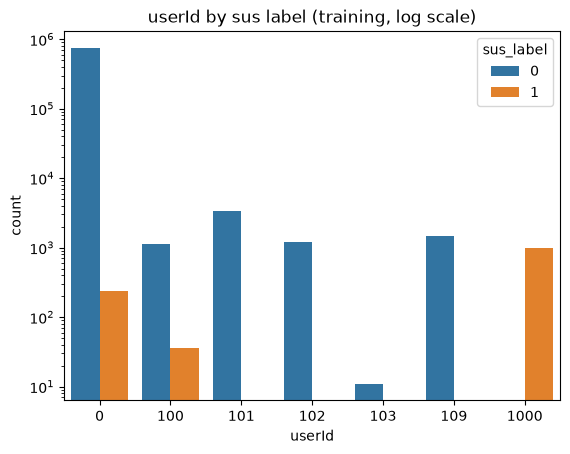

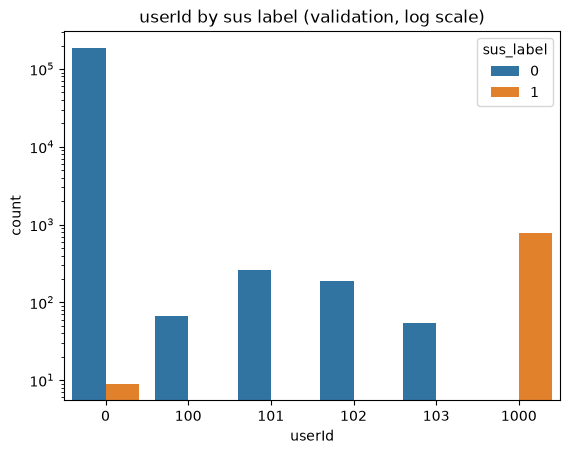

In [28]:
from endpoint_anomaly_detection_beth.plots import plot_col_by_sus
plot_col_by_sus(splits["training"], "userId", "training")
plot_col_by_sus(splits["validation"], "userId", "validation")